# AgroSense Analytics — Projeto Aplicado II (Mackenzie)
## Notebook 01: Catalogação do Acervo PlantVillage, Auditoria de Integridade e Análise Exploratória (EDA)

---

### Contexto do Projeto e Desafio Agronômico
O **AgroSense Analytics** é um projeto de Ciência de Dados aplicado ao agronegócio desenvolvido na disciplina **Projeto Aplicado II (Bacharelado em Ciência de Dados — Universidade Presbiteriana Mackenzie)**.

Estimativas internacionais e nacionais (FAO, 2021; OLIVEIRA et al., 2014) indicam que pragas e doenças reduzem significativamente o potencial produtivo agrícola (entre 20% e 40% da produção global segundo a FAO, com impactos bilionários no Brasil). O monitoramento visual manual em grandes áreas frequentemente ocorre com atraso, resultando em quebra de produtividade ou pulverizações preventivas em área total.

### Objetivos deste Caderno
1. **Diagnóstico de Ambiente:** Verificar versões das bibliotecas científicas e disponibilidade de GPU/CUDA;
2. **Catalogação do Acervo PlantVillage:** Validar as 54.305 imagens distribuídas em 38 classes e 14 culturas (HUGHES; SALATHÉ, 2015), garantindo padronização RGB e integridade do catálogo `data/metadados_plantvillage.csv`;
3. **Análise Exploratória (EDA):**
   - Distribuição de frequência das 38 classes e desbalanceamento de **36,23 : 1**;
   - Censo sanitário global (**39.221 folhas infectadas [72,22%]** vs. **15.084 sadias [27,78%]**);
   - Mosaico morfológico de sintomas foliares e análise fotométrica RGB;
4. **Justificativa Metodológica:** Explicar por que modelos tabulares sobre metadados são inadequados (vazamento de rótulo e perda da estrutura espacial das lesões).

In [1]:
# 1. Configuração do Ambiente, Imports e Diagnóstico de Hardware
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
import torch

plt.style.use('ggplot')
sns.set_theme(style='whitegrid', palette='muted')

def fmt_int(n: int) -> str:
    return f"{int(n):,}".replace(",", ".")

def fmt_dec(val: float, dec: int = 1) -> str:
    return f"{val:.{dec}f}".replace(".", ",")

print("=" * 70)
print("AGROSENSE ANALYTICS — DIAGNÓSTICO DO AMBIENTE COMPUTACIONAL")
print("=" * 70)
print(f"Versão do Python:      {sys.version.split()[0]}")
print(f"Versão do PyTorch:     {torch.__version__}")
print(f"Versão do Pandas:      {pd.__version__}")
print(f"Versão do NumPy:       {np.__version__}")
print(f"Versão do Matplotlib:  {matplotlib.__version__}")
print(f"Versão do Pillow:      {Image.__version__}")

cuda_disponivel = torch.cuda.is_available()
print(f"Aceleração CUDA:       {'DISPONÍVEL' if cuda_disponivel else 'NÃO DETECTADA (MODO CPU)'}")
if cuda_disponivel:
    print(f"Dispositivo GPU:       {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"VRAM Total Dedicada:   {fmt_dec(vram_gb, 2)} GB")
print("=" * 70)

# Resolução portátil de diretórios (independente de máquina local)
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
ETAPA4_DIR = PROJECT_ROOT if PROJECT_ROOT.name == 'Etapa 4' else PROJECT_ROOT

DATA_DIR = ETAPA4_DIR / 'data'
FIGURES_DIR = ETAPA4_DIR / 'reports' / 'figures'
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Busca opcional pelo diretório bruto de imagens (PlantVillage/color)
candidates_pv = [
    ETAPA4_DIR / 'plantvillage dataset' / 'color',
    ETAPA4_DIR.parent / 'plantvillage dataset' / 'color',
    ETAPA4_DIR.parent.parent / 'plantvillage dataset' / 'color',
    Path('plantvillage dataset/color').resolve(),
    Path('../plantvillage dataset/color').resolve(),
]
DATASET_COLOR_DIR = next((p for p in candidates_pv if p.exists()), None)

print(f"Diretório de Dados:    {DATA_DIR.relative_to(ETAPA4_DIR)}/")
print(f"Diretório de Figuras:  {FIGURES_DIR.relative_to(ETAPA4_DIR)}/")
if DATASET_COLOR_DIR is not None:
    print("Acervo de Imagens:     plantvillage dataset/color (disponível localmente)")
else:
    print("Acervo de Imagens:     não detectado localmente — operando em modo catálogo (CSV)")

AGROSENSE ANALYTICS — DIAGNÓSTICO DO AMBIENTE COMPUTACIONAL
Versão do Python:      3.12.3
Versão do PyTorch:     2.6.0+cu124
Versão do Pandas:      3.0.5
Versão do NumPy:       2.5.2
Versão do Matplotlib:  3.11.1
Versão do Pillow:      12.3.0
Aceleração CUDA:       DISPONÍVEL
Dispositivo GPU:       NVIDIA GeForce RTX 3060
VRAM Total Dedicada:   12,00 GB
Diretório de Dados:    data/
Diretório de Figuras:  reports\figures/
Acervo de Imagens:     plantvillage dataset/color (disponível localmente)


---
## 2. Varredura Física e Catalogação do Acervo PlantVillage

O acervo **PlantVillage** (Hughes & Salathé, 2015) em versão colorida consiste em fotografias capturadas em ambiente controlado de folhas de diversas culturas agrícolas comerciais (maçã, tomate, batata, milho, uva, pimentão, morango, etc.), catalogadas em pastas cuja nomenclatura obedece à convenção:
$$\text{Especie}\ \text{\_\_\_}\ \text{Condicao\_Fitossanitaria}$$

### Tratamento Defensivo de Canais de Cor e Integridade
Em Visão Computacional, variações no modo de armazenamento de imagens (como a presença inesperada de canais alfa de transparência `RGBA`, imagens em escala de cinza `L` ou paletas indexadas `P`) podem provocar falhas catastróficas em camadas de convolução 2D parametrizadas para entrada tri-canal ($C=3$).

Para neutralizar esse risco, nossa rotina realiza a conversão defensiva estrita:
```python
with Image.open(img_path) as im:
    if im.mode != 'RGB':
        im_rgb = im.convert('RGB')
    else:
        im_rgb = im
```
Isso garante o descarte sistemático de transparências e consolida uma representação tensorial homogênea em $256 \times 256 \times 3$ pixels.

In [2]:
# 2. Carga ou Extração do Catálogo de Metadados
CSV_OUTPUT = DATA_DIR / 'metadados_plantvillage.csv'
CSV_GZ_OUTPUT = DATA_DIR / 'metadados_plantvillage.csv.gz'

t0 = time.time()

if CSV_OUTPUT.exists():
    print(f"Carregando catálogo estruturado: {CSV_OUTPUT.relative_to(ETAPA4_DIR)}")
    df = pd.read_csv(CSV_OUTPUT)
elif CSV_GZ_OUTPUT.exists():
    print(f"Carregando catálogo compactado: {CSV_GZ_OUTPUT.relative_to(ETAPA4_DIR)}")
    df = pd.read_csv(CSV_GZ_OUTPUT)
    df.to_csv(CSV_OUTPUT, index=False, encoding='utf-8')
elif DATASET_COLOR_DIR is not None:
    print("Extraindo metadados diretamente das imagens brutas...")
    classes_dirs = sorted([d for d in DATASET_COLOR_DIR.iterdir() if d.is_dir()])
    records = []
    for cls_dir in classes_dirs:
        class_folder = cls_dir.name
        especie, condicao = class_folder.split('___')
        is_healthy = (condicao.lower() == 'healthy')
        for img_file in cls_dir.iterdir():
            if img_file.is_file() and img_file.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                size_kb = round(img_file.stat().st_size / 1024.0, 2)
                rel_path = f"plantvillage dataset/color/{class_folder}/{img_file.name}"
                with Image.open(img_file) as im:
                    largura, altura = im.size
                    formato = im.format if im.format else 'JPEG'
                    espaco_cores = im.mode
                    qtd_canais = len(im.getbands())
                    arr = np.asarray(im.convert('RGB'), dtype=np.float32)
                    medias = arr.mean(axis=(0, 1))
                    desvios = arr.std(axis=(0, 1))
                records.append({
                    'caminho_arquivo': rel_path, 'nome_arquivo': img_file.name,
                    'especie_cultura': especie, 'condicao_sanitaria': condicao,
                    'classe_rotulo': class_folder, 'is_saudavel': is_healthy,
                    'largura_px': largura, 'altura_px': altura, 'total_pixels': largura * altura,
                    'qtd_canais': qtd_canais, 'espaco_cores': espaco_cores,
                    'tamanho_arquivo_kb': size_kb, 'formato_arquivo': formato,
                    'media_canal_r': round(float(medias[0]), 2),
                    'media_canal_g': round(float(medias[1]), 2),
                    'media_canal_b': round(float(medias[2]), 2),
                    'desvio_canal_r': round(float(desvios[0]), 2),
                    'desvio_canal_g': round(float(desvios[1]), 2),
                    'desvio_canal_b': round(float(desvios[2]), 2)
                })
    df = pd.DataFrame(records)
    df.to_csv(CSV_OUTPUT, index=False, encoding='utf-8')
    df.to_csv(CSV_GZ_OUTPUT, index=False, compression='gzip', encoding='utf-8')
else:
    raise FileNotFoundError(
        "Nem 'data/metadados_plantvillage.csv' nem 'plantvillage dataset/color' foram encontrados."
    )

if DATASET_COLOR_DIR is not None:
    classes_dirs = sorted([d for d in DATASET_COLOR_DIR.iterdir() if d.is_dir()])
    print(f"Classes verificadas em disco: {len(classes_dirs)}")

print(f"Catálogo pronto em {time.time() - t0:.2f}s | Amostras: {fmt_int(len(df))} | Classes: {df['classe_rotulo'].nunique()} | Dimensões: {df.shape}")
df.head(3)

Carregando catálogo estruturado: data\metadados_plantvillage.csv
Classes verificadas em disco: 38
Catálogo pronto em 0.14s | Amostras: 54.305 | Classes: 38 | Dimensões: (54305, 19)


,caminho_arquivo,nome_arquivo,especie_cultura,condicao_sanitaria,classe_rotulo,is_saudavel,largura_px,altura_px,total_pixels,qtd_canais,espaco_cores,tamanho_arquivo_kb,formato_arquivo,media_canal_r,media_canal_g,media_canal_b,desvio_canal_r,desvio_canal_g,desvio_canal_b
0,plantvillage dataset/color/Apple___Apple_scab/...,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,9.39,JPEG,110.66,130.18,119.86,44.75,35.31,57.45
1,plantvillage dataset/color/Apple___Apple_scab/...,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,9.87,JPEG,84.16,97.56,103.14,30.02,23.17,47.93
2,plantvillage dataset/color/Apple___Apple_scab/...,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Sc...,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,11.72,JPEG,92.54,125.73,116.03,34.04,30.81,37.41


---
## 3. Análise Exploratória de Dados (EDA) — Distribuição de Frequência das Classes

Uma etapa fulcral na concepção de sistemas preditivos é a avaliação da simetria da variável-alvo. O dataset PlantVillage apresenta uma distribuição marcadamente heterogênea entre as classes:

- **Classe Majoritária:** `Orange___Haunglongbing_(Citrus_greening)` — $5.507$ amostras (~$10,14\%$ do acervo);
- **Classe Minoritária:** `Potato___healthy` — $152$ amostras (~$0,28\%$ do acervo);
- **Razão de Desbalanceamento Extremo:**
  $$\text{Imbalance Ratio} = \frac{5.507}{152} \approx 36,23 : 1$$

### Implicações Críticas para a Modelagem
Em classificadores neurais supervisionados treinados com funções de perda convencionais (como a *CrossEntropyLoss* padrão sem ponderação), classes super-representadas geram magnitudes de gradiente desproporcionalmente altas, forçando a rede a ignorar as classes raras para minimizar a perda média global. 

Essa evidência empírica torna **obrigatórias** duas decisões arquiteturais:
1. **Particionamento Estratificado:** Assegurar que os 70% de treino, 15% de validação e 15% de teste preservem exatamente as proporções marginais de cada uma das 38 classes;
2. **Ponderação Inversa de Perda (*Class-Weighted CrossEntropyLoss*):** Atribuir pesos inversamente proporcionais à frequência das classes, penalizando severamente erros cometidos em classes minoritárias.

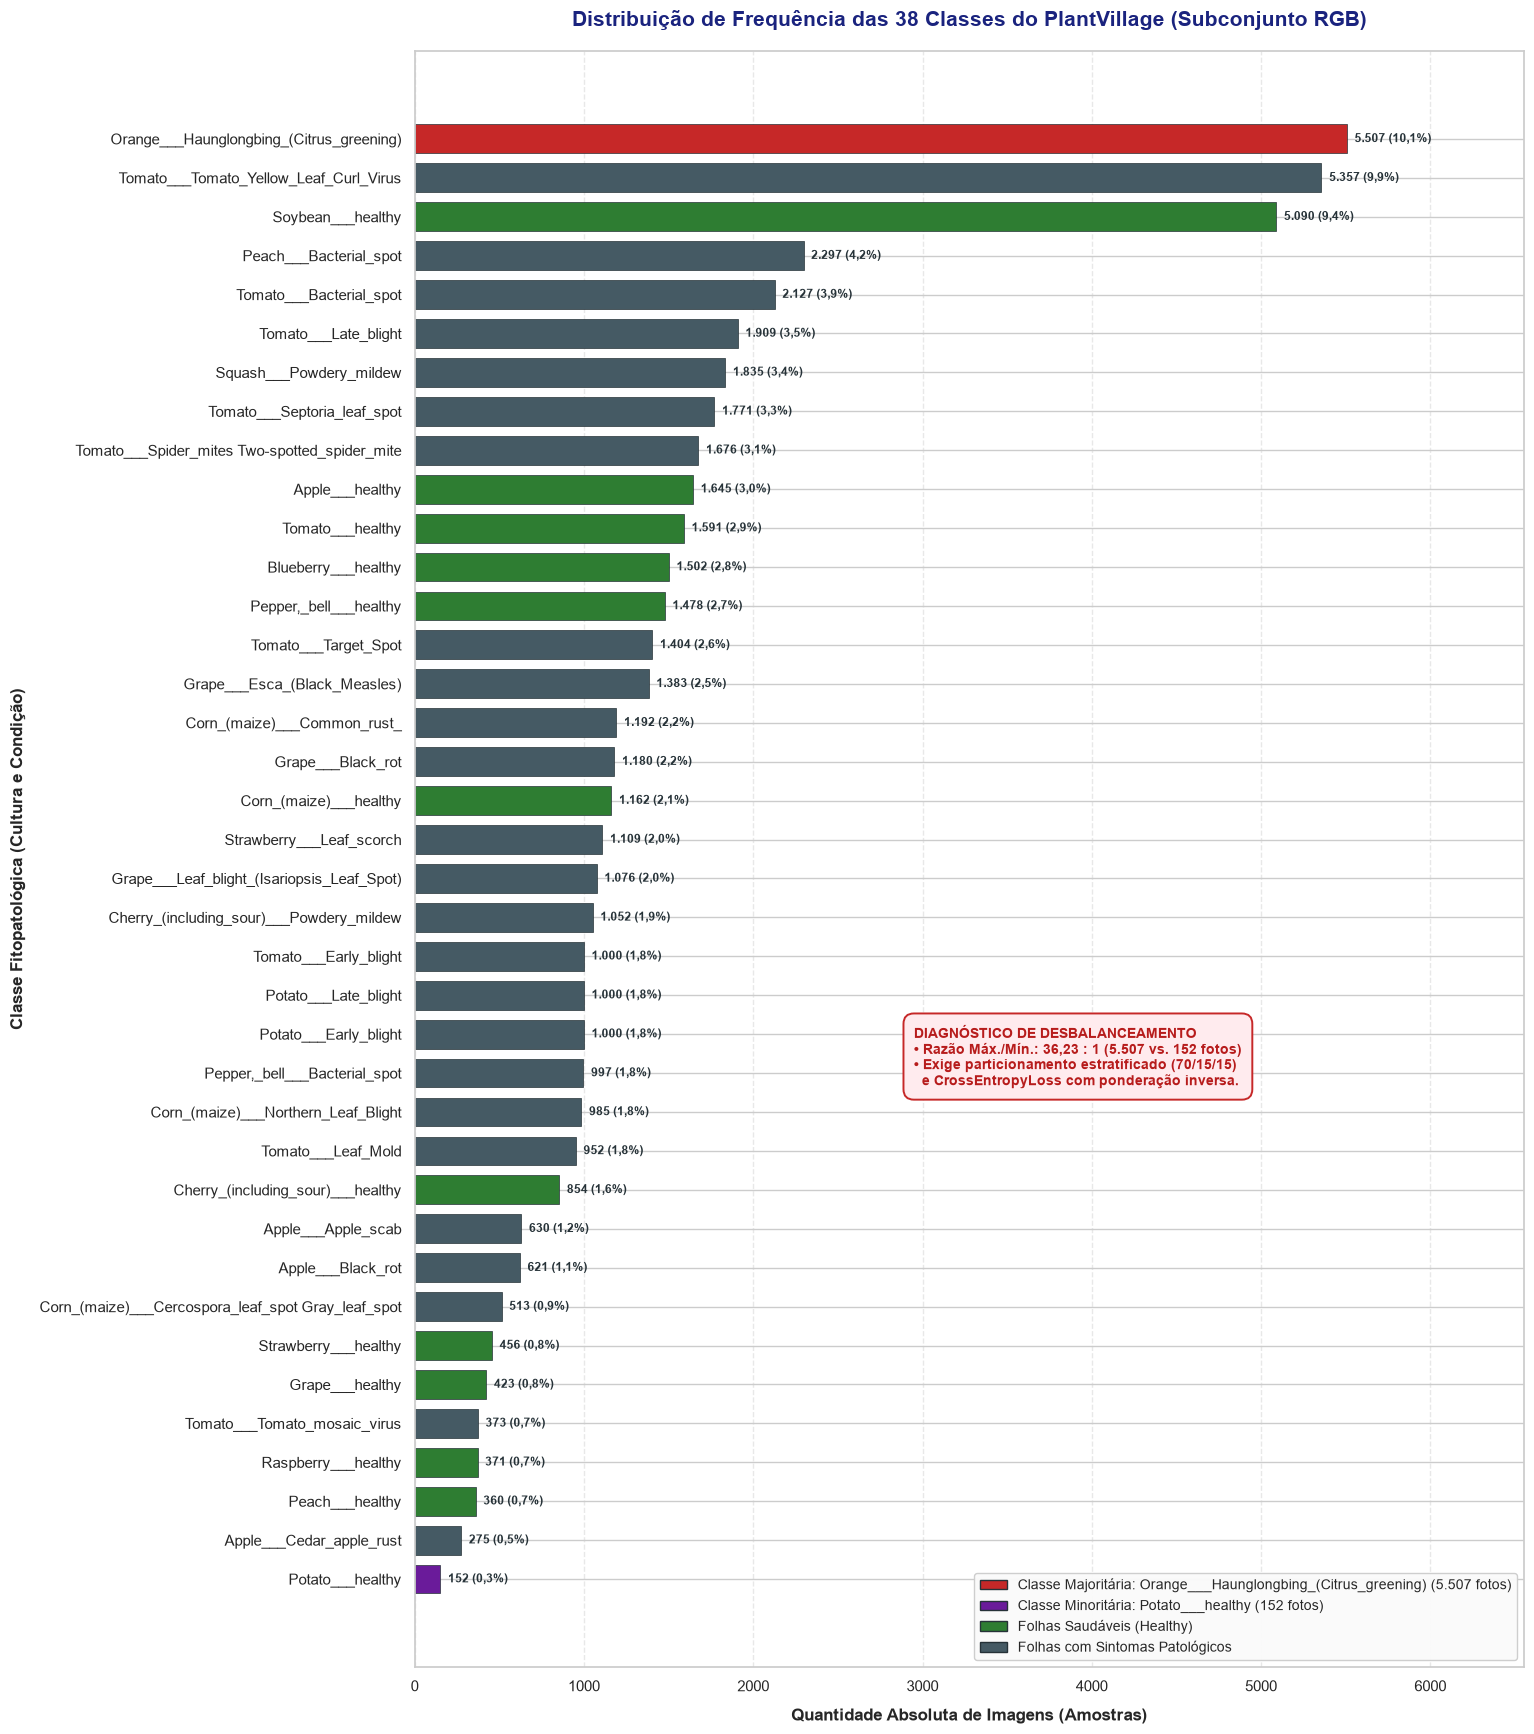

Figura salva: reports\figures\eda_distribuicao_classes.png (842.7 KB, 300 DPI)


In [3]:
# 3. Geração da Figura: Distribuição das 38 Classes e Desbalanceamento (PT-BR, sem corte)
fig_path_1 = FIGURES_DIR / 'eda_distribuicao_classes.png'

counts = df['classe_rotulo'].value_counts(ascending=True)
total_imgs = len(df)
max_cls = counts.index[-1]
min_cls = counts.index[0]
ratio = counts[max_cls] / counts[min_cls]

fig, ax = plt.subplots(figsize=(15.5, 17.5))

colors = []
for cls in counts.index:
    if cls == max_cls:
        colors.append('#c62828')  # Majoritária
    elif cls == min_cls:
        colors.append('#6a1b9a')  # Minoritária
    elif 'healthy' in cls.lower():
        colors.append('#2e7d32')  # Saudáveis
    else:
        colors.append('#455a64')  # Infectadas

bars = ax.barh(counts.index, counts.values, color=colors, edgecolor='#263238', linewidth=0.5, height=0.74)

for bar in bars:
    w = int(bar.get_width())
    y = bar.get_y() + bar.get_height() / 2
    pct = (w / total_imgs) * 100.0
    ax.text(w + 45, y, f"{fmt_int(w)} ({fmt_dec(pct, 1)}%)",
            va='center', ha='left', fontsize=8.5, fontweight='bold', color='#263238')

ax.set_xlim(0, max(counts.values) * 1.19)
ax.set_title('Distribuição de Frequência das 38 Classes do PlantVillage (Subconjunto RGB)',
             fontsize=15, fontweight='bold', pad=18, color='#1a237e')
ax.set_xlabel('Quantidade Absoluta de Imagens (Amostras)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Classe Fitopatológica (Cultura e Condição)', fontsize=12, fontweight='bold', labelpad=10)
ax.grid(axis='x', linestyle='--', alpha=0.45)

legend_elements = [
    patches.Patch(facecolor='#c62828', edgecolor='#263238', label=f'Classe Majoritária: {max_cls} ({fmt_int(counts[max_cls])} fotos)'),
    patches.Patch(facecolor='#6a1b9a', edgecolor='#263238', label=f'Classe Minoritária: {min_cls} ({fmt_int(counts[min_cls])} fotos)'),
    patches.Patch(facecolor='#2e7d32', edgecolor='#263238', label='Folhas Saudáveis (Healthy)'),
    patches.Patch(facecolor='#455a64', edgecolor='#263238', label='Folhas com Sintomas Patológicos')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9.8, framealpha=0.96, facecolor='#fafafa')

callout_text = (
    "DIAGNÓSTICO DE DESBALANCEAMENTO\n"
    f"• Razão Máx./Mín.: {fmt_dec(ratio, 2)} : 1 ({fmt_int(counts[max_cls])} vs. {fmt_int(counts[min_cls])} fotos)\n"
    "• Exige particionamento estratificado (70/15/15)\n"
    "  e CrossEntropyLoss com ponderação inversa."
)
ax.text(0.45, 0.36, callout_text, transform=ax.transAxes,
        fontsize=10.0, fontweight='bold', color='#b71c1c',
        bbox=dict(boxstyle='round,pad=0.75', facecolor='#ffebee', edgecolor='#c62828', lw=1.4))

plt.tight_layout()
fig.savefig(fig_path_1, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Figura salva: {fig_path_1.relative_to(ETAPA4_DIR)} ({os.path.getsize(fig_path_1)/1024:.1f} KB, 300 DPI)")

---
## 4. Censo Fitossanitário Foliar (Folhas Sadias vs. Infectadas)

Ao agregar as 38 classes em duas categorias macroscópicas — **Folhas Sadias (*Healthy*)** versus **Folhas Infectadas (*Diseased*)** —, obtemos a composição exata do acervo `metadados_plantvillage.csv`:
- **Folhas Infectadas (`is_saudavel == False`):** $39.221$ amostras ($72,22\%$ do acervo);
- **Folhas Sadias (`is_saudavel == True`):** $15.084$ amostras ($27,78\%$ do acervo).

Esse equilíbrio exige que o classificador mantenha alta sensibilidade tanto para detectar lesões patológicas quanto para reconhecer corretamente folhas hígidas (evitando falsos positivos que levariam a recomendações desnecessárias de pulverização).

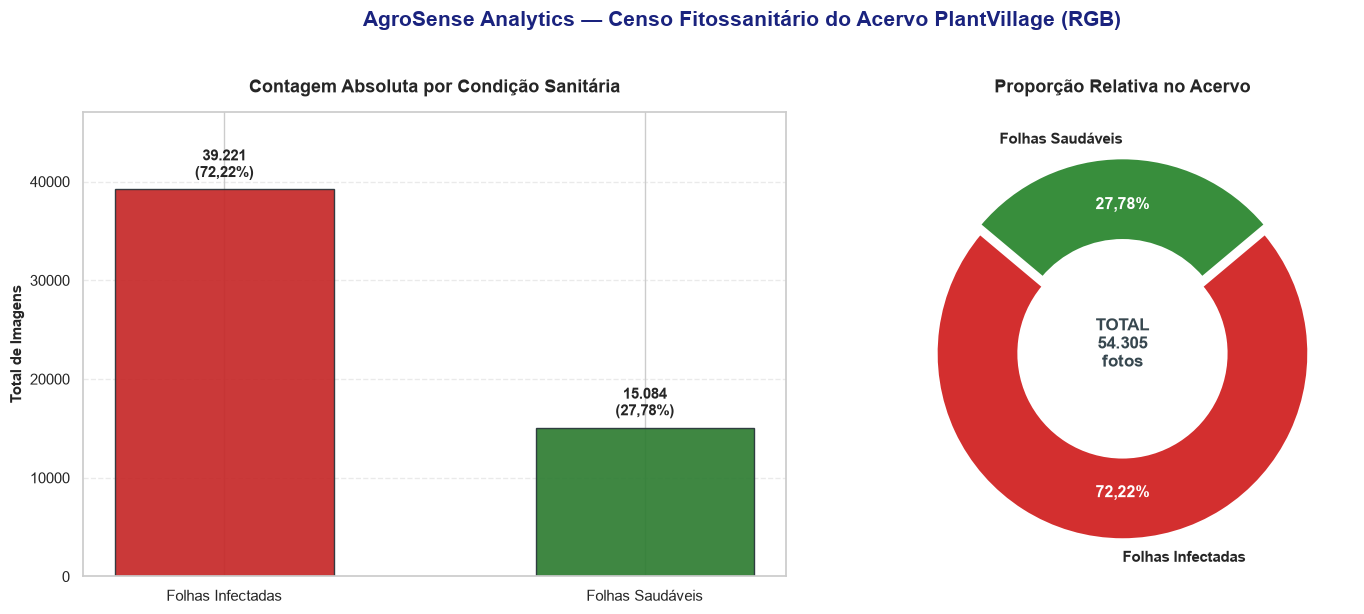

Figura salva: reports\figures\eda_status_sanitario.png (234.4 KB, 300 DPI)


In [4]:
# 4. Geração da Figura: Censo Fitossanitário do Acervo
fig_path_2 = FIGURES_DIR / 'eda_status_sanitario.png'

counts_san = df['is_saudavel'].value_counts()
total = len(df)
n_doentes = int(counts_san.get(False, 0))
n_saudaveis = int(counts_san.get(True, 0))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

labels = ['Folhas Infectadas', 'Folhas Saudáveis']
vals = [n_doentes, n_saudaveis]
bar_colors = ['#c62828', '#2e7d32']

bars = axes[0].bar(labels, vals, color=bar_colors, edgecolor='#263238', width=0.52, alpha=0.92)
for bar in bars:
    h = int(bar.get_height())
    pct = (h / total) * 100.0
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 800, f"{fmt_int(h)}\n({fmt_dec(pct, 2)}%)",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

axes[0].set_ylim(0, max(vals) * 1.20)
axes[0].set_title('Contagem Absoluta por Condição Sanitária', fontsize=13, fontweight='bold', pad=14)
axes[0].set_ylabel('Total de Imagens', fontsize=11, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

pie_colors = ['#d32f2f', '#388e3c']
wedges, texts, autotexts = axes[1].pie(
    vals,
    labels=labels,
    autopct=lambda p: f"{fmt_dec(p, 2)}%",
    startangle=140,
    colors=pie_colors,
    explode=(0.05, 0.0),
    wedgeprops=dict(width=0.44, edgecolor='white', linewidth=1.5),
    pctdistance=0.75
)
for at in autotexts:
    at.set_color('white')
    at.set_fontsize(11.5)
    at.set_fontweight('bold')
for t in texts:
    t.set_fontsize(10.5)
    t.set_fontweight('bold')

axes[1].text(0, 0, f"TOTAL\n{fmt_int(total)}\nfotos", ha='center', va='center', fontsize=12, fontweight='bold', color='#37474f')
axes[1].set_title('Proporção Relativa no Acervo', fontsize=13, fontweight='bold', pad=14)

plt.suptitle('AgroSense Analytics — Censo Fitossanitário do Acervo PlantVillage (RGB)',
             fontsize=15, fontweight='bold', y=1.02, color='#1a237e')
plt.tight_layout()
fig.savefig(fig_path_2, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Figura salva: {fig_path_2.relative_to(ETAPA4_DIR)} ({os.path.getsize(fig_path_2)/1024:.1f} KB, 300 DPI)")

---
## 5. Mosaico Morfológico de Lesões Fitopatológicas

Fitopatologias exibem manifestações macroscópicas altamente distintas na lâmina foliar. Compreender essas assinaturas clínicas orienta o projeto de redes neurais convolucionais (CNNs):
- **Necrose Concentrica (*Target Spot* no Tomate):** Lesões marrons escuras com anéis concêntricos que se assemelham a um alvo;
- **Clorose e Enrolamento Foliar (*TYLCV* no Tomate):** Degradação da clorofila gerando amarelecimento internerval e redução da área foliar fotossintética;
- **Pústulas Alaranjadas (*Common Rust* no Milho):** Formação de pústulas epidérmicas proeminentes que rompem o tecido foliar;
- **Micélio Pulverulento (*Powdery Mildew* na Abóbora):** Revestimento fúngico esbranquiçado superficial;
- **Queima Foliar (*Late Blight* na Batata):** Lesões aquosas de expansão rápida que resultam no colapso do parênquima foliar.

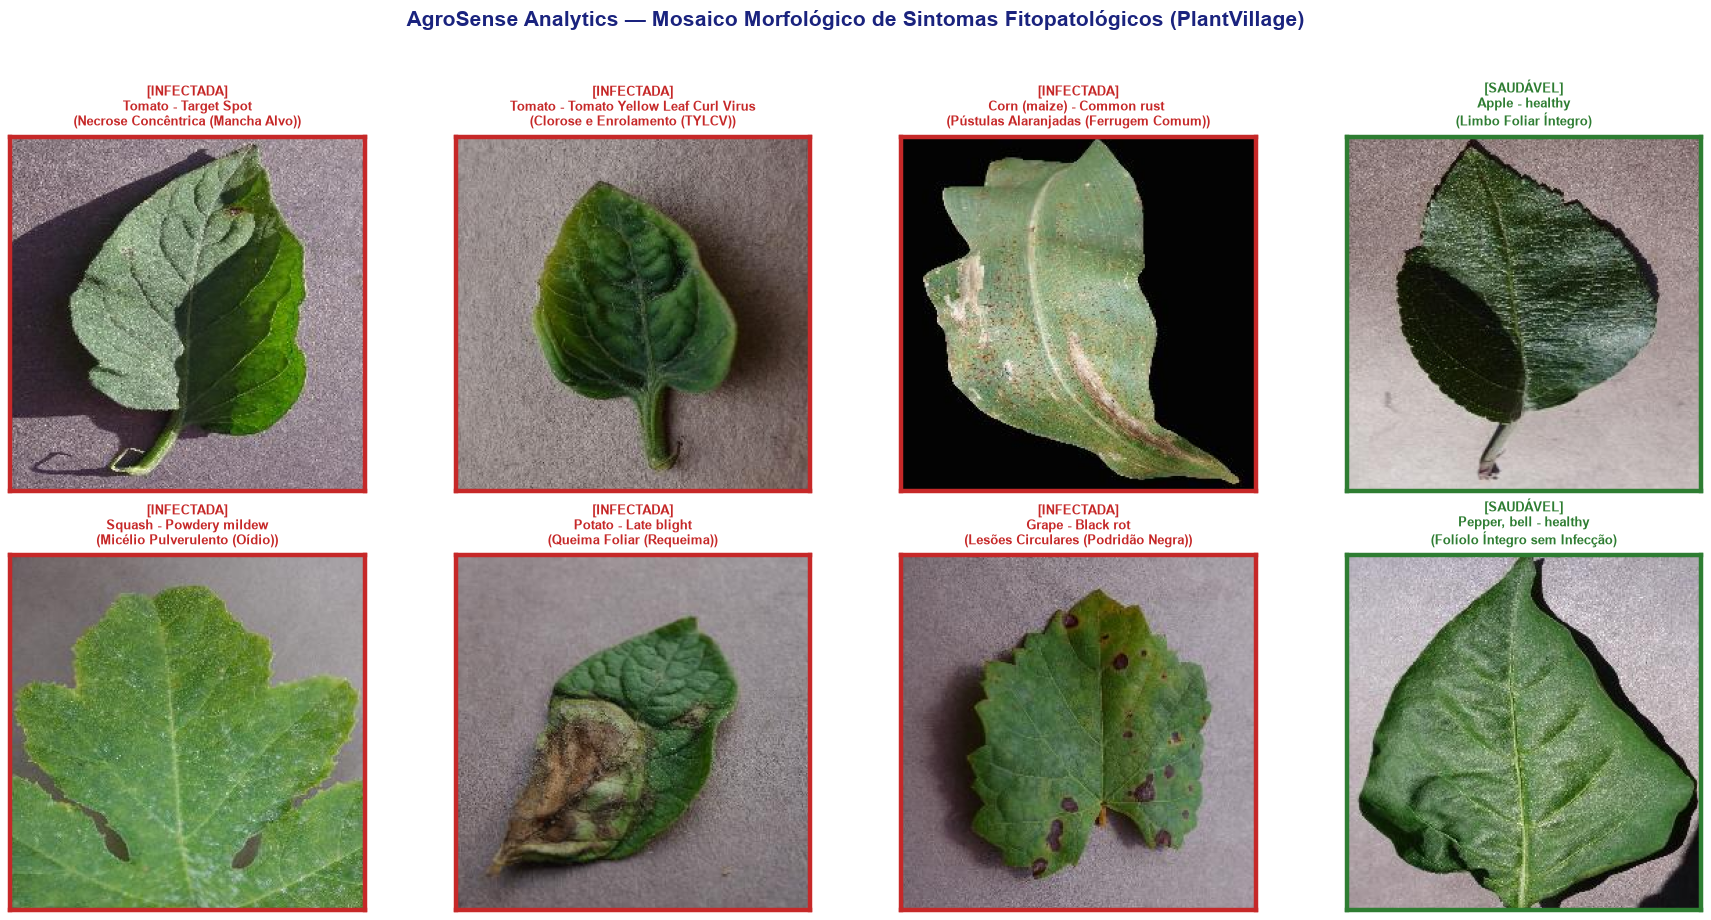

Figura salva: reports\figures\eda_mosaico_patologias.png (1619.7 KB, 300 DPI)


In [5]:
# 5. Geração da Figura: Mosaico Morfológico de Sintomas Fitopatológicos
fig_path_3 = FIGURES_DIR / 'eda_mosaico_patologias.png'

curated_samples = [
    ('Tomato___Target_Spot', 'Necrose Concêntrica (Mancha Alvo)', False),
    ('Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Clorose e Enrolamento (TYLCV)', False),
    ('Corn_(maize)___Common_rust_', 'Pústulas Alaranjadas (Ferrugem Comum)', False),
    ('Apple___healthy', 'Limbo Foliar Íntegro', True),
    ('Squash___Powdery_mildew', 'Micélio Pulverulento (Oídio)', False),
    ('Potato___Late_blight', 'Queima Foliar (Requeima)', False),
    ('Grape___Black_rot', 'Lesões Circulares (Podridão Negra)', False),
    ('Pepper,_bell___healthy', 'Folíolo Íntegro sem Infecção', True)
]

if DATASET_COLOR_DIR is not None:
    base_dir = DATASET_COLOR_DIR.parent.parent
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    axes = axes.flatten()

    for idx, (cls_name, sintoma, is_healthy) in enumerate(curated_samples):
        sub = df[df['classe_rotulo'] == cls_name]
        img_path = base_dir / sub.iloc[0]['caminho_arquivo']
        with Image.open(img_path) as im:
            axes[idx].imshow(im.convert('RGB'))
        axes[idx].set_xticks([])
        axes[idx].set_yticks([])

        border_color = '#2e7d32' if is_healthy else '#c62828'
        status_tag = "[SAUDÁVEL]" if is_healthy else "[INFECTADA]"
        for spine in axes[idx].spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(3.2)

        clean_cls = cls_name.replace('___', ' - ').replace('_', ' ')
        axes[idx].set_title(f"{status_tag}\n{clean_cls}\n({sintoma})", fontsize=9.5, fontweight='bold', color=border_color, pad=8)

    plt.suptitle('AgroSense Analytics — Mosaico Morfológico de Sintomas Fitopatológicos (PlantVillage)',
                 fontsize=15, fontweight='bold', y=1.02, color='#1a237e')
    plt.tight_layout()
    fig.savefig(fig_path_3, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"Figura salva: {fig_path_3.relative_to(ETAPA4_DIR)} ({os.path.getsize(fig_path_3)/1024:.1f} KB, 300 DPI)")
elif fig_path_3.exists():
    print(f"Modo catálogo (sem imagens brutas): preservando mosaico existente em {fig_path_3.relative_to(ETAPA4_DIR)}.")
else:
    print("Aviso: adicione 'plantvillage dataset/color' localmente para gerar o mosaico de imagens.")

---
## 6. Assinatura Fotométrica e Análise Espectral dos Canais R, G e B

A degradação fisiológica provocada por fungos, bactérias e vírus compromete os cloroplastos no mesófilo foliar. Folhas sadias exibem forte absorção nas faixas do azul (~450 nm) e vermelho (~670 nm), refletindo predominantemente a luz verde (~550 nm). Quando infectadas:
1. A **morte celular e necrose** geram aumento na refletância do canal **Vermelho (Red)** decorrente da perda de clorofila;
2. As curvas de densidade dos canais fotométricos revelam alterações espectrais observáveis, embora exista substancial sobreposição em valores agregados.

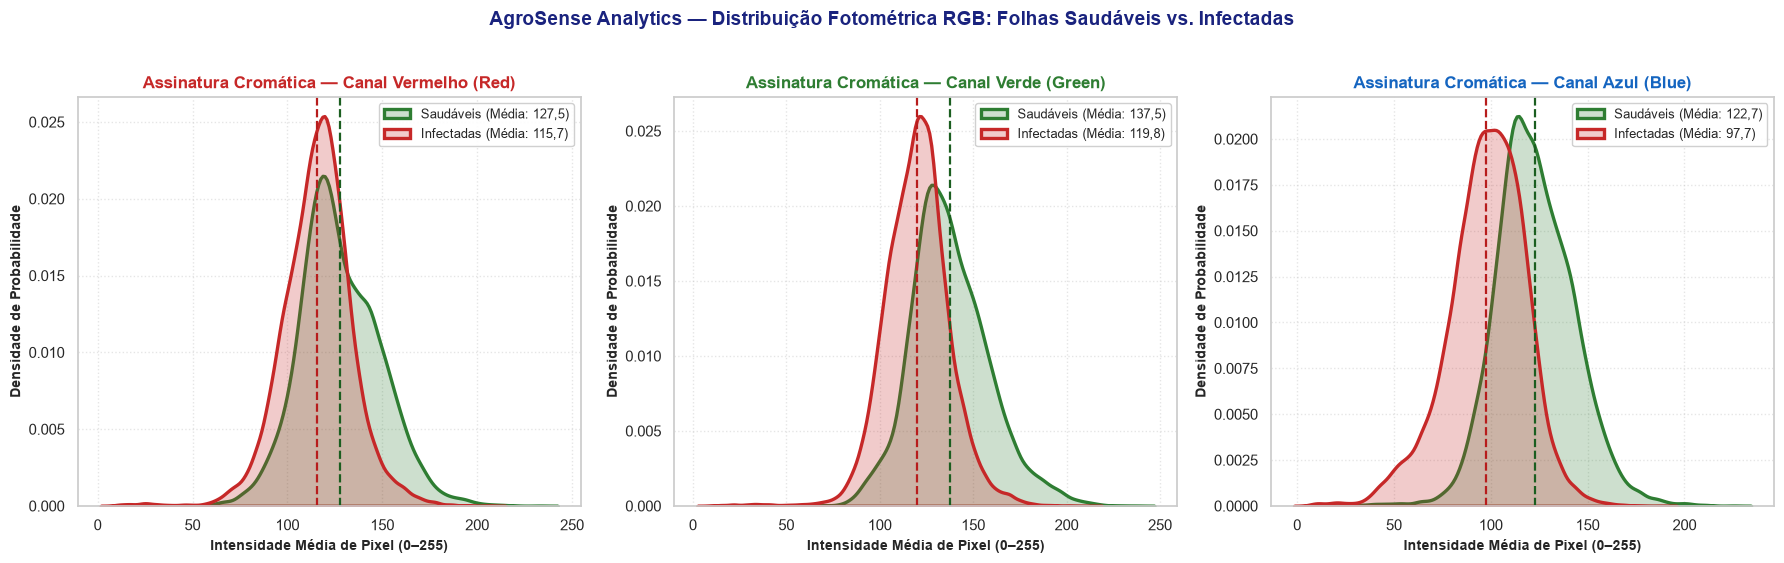

Figura salva: reports\figures\eda_distribuicao_rgb.png (503.2 KB, 300 DPI)


In [6]:
# 6. Geração da Figura: Assinatura Fotométrica Espectral (RGB)
fig_path_4 = FIGURES_DIR / 'eda_distribuicao_rgb.png'

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
canais = [
    ('media_canal_r', 'Canal Vermelho (Red)', '#c62828'),
    ('media_canal_g', 'Canal Verde (Green)', '#2e7d32'),
    ('media_canal_b', 'Canal Azul (Blue)', '#1565c0')
]

saudaveis = df[df['is_saudavel'] == True]
doentes = df[df['is_saudavel'] == False]

for idx, (col, titulo, canal_cor) in enumerate(canais):
    v_h = saudaveis[col]
    v_d = doentes[col]

    sns.kdeplot(v_h, ax=axes[idx], color='#2e7d32', lw=2.4, label=f'Saudáveis (Média: {fmt_dec(v_h.mean(), 1)})', fill=True, alpha=0.24)
    sns.kdeplot(v_d, ax=axes[idx], color='#c62828', lw=2.4, label=f'Infectadas (Média: {fmt_dec(v_d.mean(), 1)})', fill=True, alpha=0.24)
    axes[idx].axvline(v_h.mean(), color='#1b5e20', linestyle='--', lw=1.6)
    axes[idx].axvline(v_d.mean(), color='#b71c1c', linestyle='--', lw=1.6)

    axes[idx].set_title(f'Assinatura Cromática — {titulo}', fontsize=12, fontweight='bold', color=canal_cor)
    axes[idx].set_xlabel('Intensidade Média de Pixel (0–255)', fontsize=10, fontweight='bold')
    axes[idx].set_ylabel('Densidade de Probabilidade', fontsize=10, fontweight='bold')
    axes[idx].legend(loc='upper right', fontsize=9.5, framealpha=0.92)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('AgroSense Analytics — Distribuição Fotométrica RGB: Folhas Saudáveis vs. Infectadas',
             fontsize=14, fontweight='bold', y=1.02, color='#1a237e')
plt.tight_layout()
fig.savefig(fig_path_4, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Figura salva: {fig_path_4.relative_to(ETAPA4_DIR)} ({os.path.getsize(fig_path_4)/1024:.1f} KB, 300 DPI)")

---
## 7. Síntese Técnica e Justificativa de Engenharia de Dados

### Por que a tabela de metadados NÃO serve como entrada de modelo preditivo tabular?
Um erro conceitual comum em projetos de Visão Computacional é tentar alimentar modelos tabulares clássicos (como *Random Forest*, *XGBoost* ou *Regressão Logística*) com tabelas resumo de metadados extraídos de imagens (como médias e desvios de canais R, G e B, largura, altura ou tamanho em KB).

Na arquitetura do **AgroSense Analytics**, descartamos essa abordagem com base em três pilares formais de Ciência de Dados:

1. **Vazamento Determinístico de Alvo (*Target Leakage*):**
   - Atributos como `caminho_arquivo`, `nome_arquivo` e `especie_cultura` contêm substrings diretas da patologia (ex.: `Tomato___Early_blight`). Qualquer modelo tabular que utilize tais colunas aprenderia atalhos triviais (*spurious correlations*), alcançando 100% de acurácia espúria em treino e teste sem possuir capacidade real de generalização visual sobre novas fotografias foliares inéditas.

2. **Colapso Irreversível da Topologia Espacial e Textura:**
   - A redução de uma matriz bidimensional de $256 \times 256$ pixels (composta por $65.536$ pontos de amostragem espacial por canal de cor) a meros valores escalares (média e desvio padrão global) destrói completamente:
     * O **formato geométrico das lesões** (ex.: halos concêntricos de *Target Spot* vs. pontuações dispersas de *Bacterial Spot*);
     * A **distribuição de bordas e gradientes espaciais**;
     * As **texturas fúngicas** e a localização relativa das pústulas sobre as nervuras.
   - Folhas de plantas completamente distintas infectadas por doenças diferentes podem apresentar a exata mesma média RGB global, tornando-as indistinguíveis no espaço de características puramente estatístico.

3. **Mandato da Modelagem Convolucional Profunda (*Deep CNN*):**
   - Redes Neurais Convolucionais profundas (como a **MobileNetV2**) operam diretamente sobre o tensor bruto de imagem $X \in \mathbb{R}^{3 \times 224 \times 224}$, preservando relações de invariância translacional e extraindo hierarquias de filtros espaciais — desde detectores de borda nas camadas iniciais até detectores morfológicos complexos de sintomas fitopatológicos nas camadas profundas.

Portanto, o arquivo `metadados_plantvillage.csv` cumpre a função estrita de **governança de dados, auditoria de catálogo e indexação de amostragem**, enquanto a inferência preditiva é delegada integralmente à esteira de Deep Learning desenvolvida nos Cadernos 02 e 03.

In [7]:
# 8. Verificação dos Artefatos Gerados no Notebook 01
print("=" * 70)
print("VERIFICAÇÃO DE ARTEFATOS — NOTEBOOK 01")
print("=" * 70)

required_artifacts = [
    DATA_DIR / 'metadados_plantvillage.csv',
    FIGURES_DIR / 'eda_distribuicao_classes.png',
    FIGURES_DIR / 'eda_status_sanitario.png',
    FIGURES_DIR / 'eda_mosaico_patologias.png',
    FIGURES_DIR / 'eda_distribuicao_rgb.png'
]

for art in required_artifacts:
    assert art.exists() and art.stat().st_size > 10_000, f"Artefato ausente ou inválido: {art.name}"
    print(f"[OK] {art.name:32s} | {str(art.relative_to(ETAPA4_DIR)):40s} | {art.stat().st_size/1024:7.1f} KB")
print("=" * 70)

VERIFICAÇÃO DE ARTEFATOS — NOTEBOOK 01
[OK] metadados_plantvillage.csv       | data\metadados_plantvillage.csv          | 15835.9 KB
[OK] eda_distribuicao_classes.png     | reports\figures\eda_distribuicao_classes.png |   842.7 KB
[OK] eda_status_sanitario.png         | reports\figures\eda_status_sanitario.png |   234.4 KB
[OK] eda_mosaico_patologias.png       | reports\figures\eda_mosaico_patologias.png |  1619.7 KB
[OK] eda_distribuicao_rgb.png         | reports\figures\eda_distribuicao_rgb.png |   503.2 KB
